XÂY DỰNG DECISION TREE

- Huấn luyện cây ban đầu

In [3]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

thu_muc = r"C:\Users\hauth\OneDrive\Tài liệu\GitHub\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\BÀI TẬP NHÓM HẰNG TUẦN\LAB5 BÀI TOÁN PHÂN LỚP (NHÓM)\THUẬT TOÁN PHÂN LỚP\Thanh\processed"

X_train = pd.read_csv(f"{thu_muc}/X_train.csv")
y_train = pd.read_csv(f"{thu_muc}/y_train.csv")["diabetes"]
X_test = pd.read_csv(f"{thu_muc}/X_test.csv")
y_test = pd.read_csv(f"{thu_muc}/y_test.csv")["diabetes"]

# Huấn luyện cây quyết định ban đầu với tham số mặc định
model_tree = DecisionTreeClassifier(random_state=42)
model_tree.fit(X_train, y_train)

y_pred = model_tree.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9510140405616224

Classification report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17534
           1       0.72      0.73      0.72      1696

    accuracy                           0.95     19230
   macro avg       0.85      0.85      0.85     19230
weighted avg       0.95      0.95      0.95     19230

Confusion matrix:
[[17052   482]
 [  460  1236]]


- Tinh chỉnh tham số

In [4]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

tham_so = {
    "criterion": ["gini", "entropy"],
    "max_depth": [None, 5, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "ccp_alpha": [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
    "class_weight": [None, "balanced"],
}

chia_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

tim_kiem = RandomizedSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_distributions=tham_so,
    n_iter=40,
    scoring="f1_macro",
    cv=chia_cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    refit=True
)

tim_kiem.fit(X_train, y_train)
model_tree_tuned = tim_kiem.best_estimator_

print("Tham số tốt nhất:", tim_kiem.best_params_)
print("F1-macro tốt nhất trên cross-validation:", tim_kiem.best_score_)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Tham số tốt nhất: {'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': None, 'criterion': 'entropy', 'class_weight': None, 'ccp_alpha': 1e-05}
F1-macro tốt nhất trên cross-validation: 0.9794466475301565


In [3]:
pred_goc = model_tree.predict(X_test)
pred_tinh_chinh = model_tree_tuned.predict(X_test)

print("Số dự đoán khác nhau:",
      (pred_goc != pred_tinh_chinh).sum())
print("Accuracy cây ban đầu:", accuracy_score(y_test, pred_goc))
print("Accuracy cây tinh chỉnh:", accuracy_score(y_test, pred_tinh_chinh))

Số dự đoán khác nhau: 717
Accuracy cây ban đầu: 0.9510140405616224
Accuracy cây tinh chỉnh: 0.9484659386375455


- Đánh giá mô hình

In [4]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

for ten, model in [
    ("Cây ban đầu", model_tree),
    ("Cây đã tinh chỉnh", model_tree_tuned),
]:
    y_pred = model.predict(X_test)

    print(f"\n===== {ten} =====")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("F1-macro:", f1_score(y_test, y_pred, average="macro"))
    print("Classification report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred))


===== Cây ban đầu =====
Accuracy: 0.9510140405616224
F1-macro: 0.8485991847821999
Classification report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17534
           1       0.72      0.73      0.72      1696

    accuracy                           0.95     19230
   macro avg       0.85      0.85      0.85     19230
weighted avg       0.95      0.95      0.95     19230

Confusion matrix:
[[17052   482]
 [  460  1236]]

===== Cây đã tinh chỉnh =====
Accuracy: 0.9484659386375455
F1-macro: 0.8435711303037405
Classification report:
              precision    recall  f1-score   support

           0       0.97      0.97      0.97     17534
           1       0.70      0.73      0.72      1696

    accuracy                           0.95     19230
   macro avg       0.84      0.85      0.84     19230
weighted avg       0.95      0.95      0.95     19230

Confusion matrix:
[[16993   541]
 [  450  1246]]


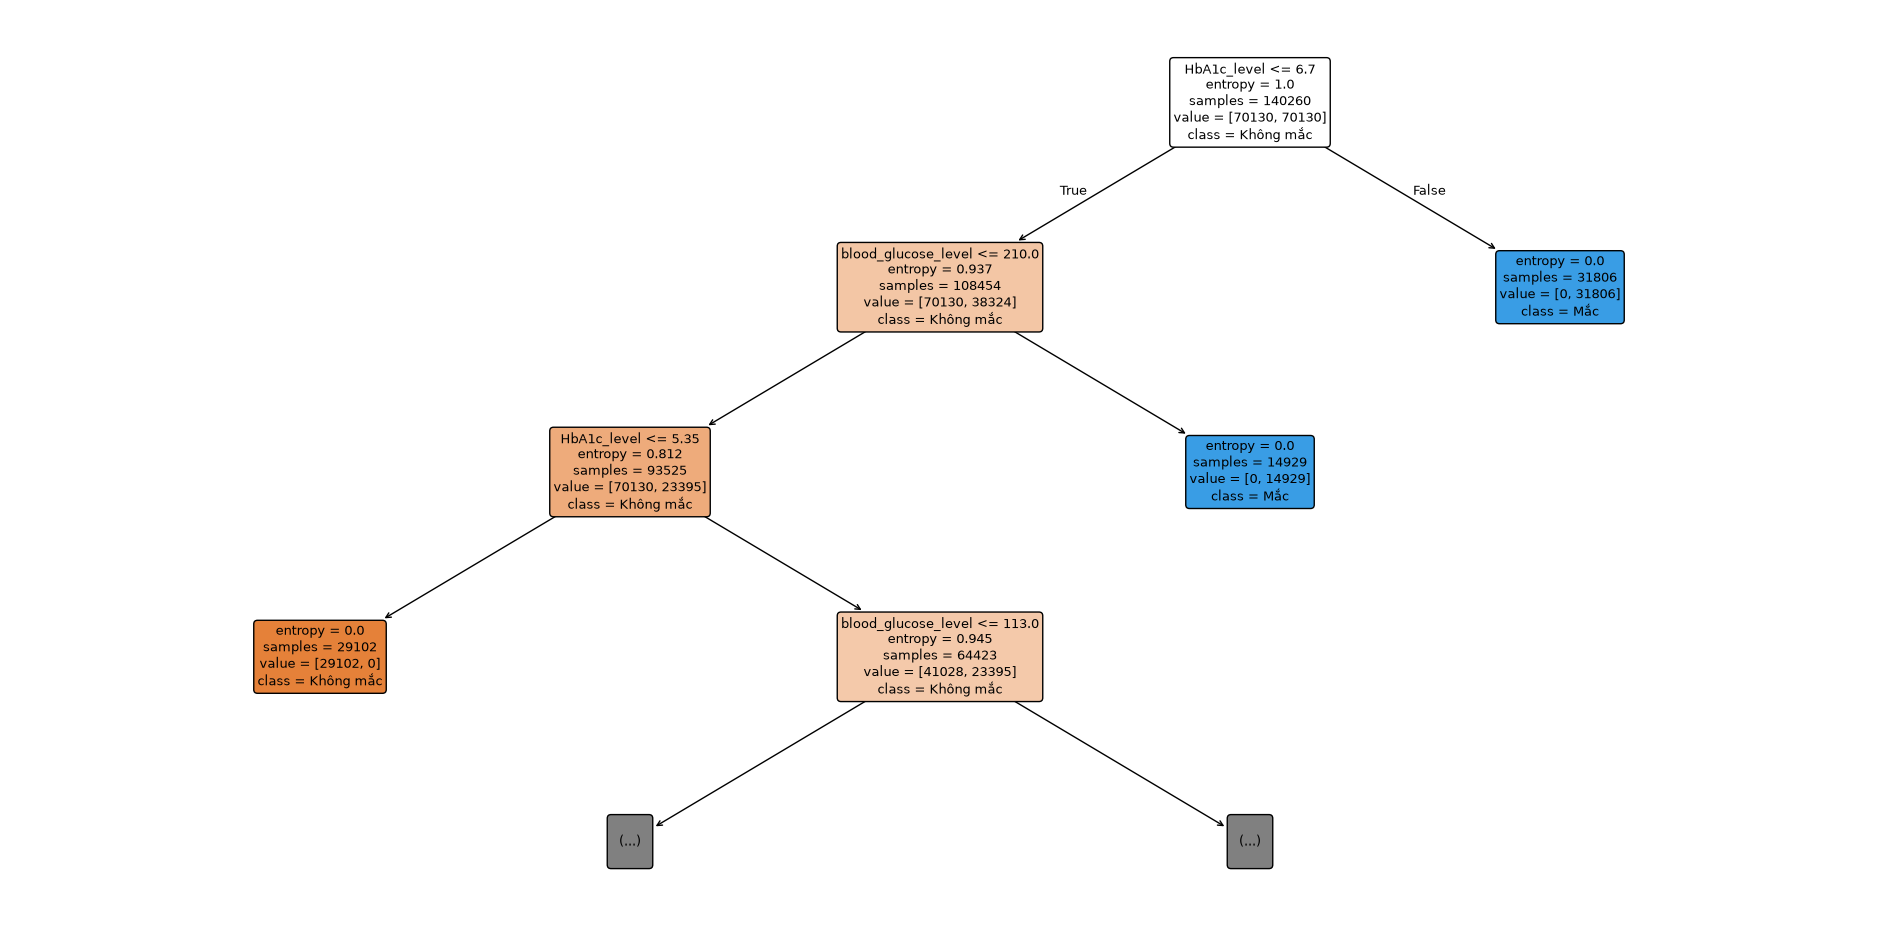

In [6]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))
plot_tree(
    model_tree_tuned,
    feature_names=list(X_train.columns),
    class_names=["Không mắc", "Mắc"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)
plt.show()